# FD003 — diagnostic run: why does the search objective disagree with the test?

**This is not a paper experiment.** It is an internal diagnostic whose output is a decision:
*which objective should the real optimization use?* Test is used freely here for analysis, because
nothing produced here is reported as a result.

Every trial trains once and records three metrics:

| metric | role |
|---|---|
| **exhaustive validation** RMSE | what the search currently selects on |
| **test-like validation** RMSE | 1,000 randomly truncated windows from the same held-out engines |
| **test** RMSE | logged for diagnosis; `run_trial` returns only the objective to the oracle |

A likely mechanism is already visible in the data before training anything:

| set | n | mean RUL | fraction pinned at the RUL cap |
|---|---|---|---|
| exhaustive validation | 3,728 | 82.8 | **33%** |
| test-like validation | 1,000 | 79.3 | **26%** |
| official test | 100 | 73.8 | **15%** |

A third of the current objective is early-life windows where the correct answer is just the
constant 125. The test set is 15% such cases. So the objective partly scores a saturated constant
that the test barely asks about.

**What we get out of this**

1. Whether each validation set tracks test across the search, and with how much regret.
2. Which hyperparameters the objective misprices — parameters where the correlation with
   validation and with test have *opposite signs*.
3. A bake-off of candidate objectives (single, blended, size-penalised) scored by the regret they
   would have incurred, which is the recommendation for the real run.

Architecture and preprocessing are fixed to the factor-grid winner: our parallel CNN-LSTM on
Peng's preprocessing (25 features, window 50, Min-Max), baseline test 11.12 +/- 0.42.

Run from the folder containing `train_FD003.txt`.

In [1]:
import os, json, gc, time, random, math
os.environ['PYTHONHASHSEED']='42'
import numpy as np, pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error
from scipy.stats import spearmanr, pearsonr
import tensorflow as tf
for _g in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(_g,True)
    except RuntimeError as _e: print('memory growth:',_e)
from tensorflow.keras import backend as K, regularizers
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, Dropout, Dense, LSTM,
                                     Concatenate, Flatten, GlobalAveragePooling1D)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import keras_tuner as kt
def set_seeds(s):
    os.environ['PYTHONHASHSEED']=str(s); random.seed(s); np.random.seed(s)
    tf.keras.utils.set_random_seed(s)
def gpu_preflight():
    if not tf.config.list_physical_devices('GPU'): print('CPU mode'); return False
    try:
        x=np.random.rand(8,10,3).astype('float32'); y=np.random.rand(8,1).astype('float32')
        i=Input(shape=(10,3)); o=Dense(1)(GlobalAveragePooling1D()(Conv1D(4,3,padding='same')(i)))
        m=Model(i,o); m.compile('adam','mse'); m.fit(x,y,epochs=1,verbose=0); K.clear_session()
        print('GPU preflight passed'); return True
    except Exception as e:
        print('GPU preflight FAILED (%s) - CPU fallback'%type(e).__name__); K.clear_session(); return False
USE_GPU=gpu_preflight(); DEVICE='/GPU:0' if USE_GPU else '/CPU:0'
try: tf.config.experimental.enable_op_determinism()
except Exception as e: print('determinism:',e)
print('TF',tf.__version__,'| device',DEVICE)

GPU preflight passed
TF 2.10.0 | device /GPU:0


In [2]:
SEED=42; RUL_CAP=125; W=50
EPOCHS, BATCH, PATIENCE = 60, 512, 15
TRIAL_SEEDS = 2          # seeds averaged inside each trial
BO_TRIALS   = 30
FINAL_SEEDS = 5
TESTLIKE_PER_UNIT, TESTLIKE_SEED = 50, 12345   # 20 engines x 50 = 1000 samples
set_seeds(SEED)

idx=['unit_nr','time_cycles']; setn=['setting_1','setting_2','setting_3']
sn=[f's_{i}' for i in range(1,22)]; cols=idx+setn+sn
train=pd.read_csv('train_FD003.txt',sep=r'\s+',header=None,names=cols)
test =pd.read_csv('test_FD003.txt', sep=r'\s+',header=None,names=cols)
y_test=pd.read_csv('RUL_FD003.txt',sep=r'\s+',header=None,names=['RUL'])

_g=GroupShuffleSplit(n_splits=1,train_size=0.8,random_state=SEED)
_ti,_vi=next(_g.split(train,groups=train.unit_nr))
TRAIN_UNITS=np.sort(train.iloc[_ti].unit_nr.unique())
VAL_UNITS  =np.sort(train.iloc[_vi].unit_nr.unique())
assert not set(TRAIN_UNITS)&set(VAL_UNITS)

feats=setn+sn+['time_cycles']
tr=train.copy(); mx=tr.groupby('unit_nr')['time_cycles'].transform('max')
tr['RUL']=(mx-tr['time_cycles']).clip(upper=RUL_CAP)
te=test.copy()
sc=MinMaxScaler().fit(tr[tr.unit_nr.isin(TRAIN_UNITS)][feats])   # train engines only
tr[feats]=np.nan_to_num(sc.transform(tr[feats])); te[feats]=np.nan_to_num(sc.transform(te[feats]))

def win_exhaustive(df,us):
    X,y=[],[]
    for u in us:
        d=df[df.unit_nr==u]; A=d[feats].to_numpy(np.float32); L=d['RUL'].to_numpy(np.float32)
        for e in range(W,len(d)+1): X.append(A[e-W:e]); y.append(L[e-1])
    return np.asarray(X,np.float32),np.asarray(y,np.float32).reshape(-1,1)

def win_testlike(df,us,rng,per_unit):
    """Randomly truncated windows - matches how the official test trajectories are cut."""
    X,y=[],[]
    for u in us:
        d=df[df.unit_nr==u]; A=d[feats].to_numpy(np.float32); L=d['RUL'].to_numpy(np.float32)
        n=len(d)
        if n<W: continue
        for cut in rng.integers(W,n+1,size=per_unit):
            X.append(A[cut-W:cut]); y.append(L[cut-1])
    return np.asarray(X,np.float32),np.asarray(y,np.float32).reshape(-1,1)

Xtr,ytr=win_exhaustive(tr,TRAIN_UNITS)
Xve,yve=win_exhaustive(tr,VAL_UNITS)                                    # BO objective
Xvt,yvt=win_testlike(tr,VAL_UNITS,np.random.default_rng(TESTLIKE_SEED),TESTLIKE_PER_UNIT)
Xte=[]
for u in te.unit_nr.unique():
    A=te[te.unit_nr==u][feats].to_numpy(np.float32)
    Xte.append(A[-W:] if len(A)>=W else np.vstack([np.repeat(A[:1],W-len(A),axis=0),A]))
Xte=np.asarray(Xte,np.float32)
yte=np.clip(y_test['RUL'].to_numpy(np.float32),0,RUL_CAP).reshape(-1,1)

print('train %s | val-exhaustive %s | val-testlike %s | test %s'
      %(Xtr.shape,Xve.shape,Xvt.shape,Xte.shape))
print('RUL at cap: val-exhaustive %.2f | val-testlike %.2f | test %.2f'
      %(float((yve>=RUL_CAP).mean()),float((yvt>=RUL_CAP).mean()),float((yte>=RUL_CAP).mean())))
print('mean RUL  : val-exhaustive %.1f | val-testlike %.1f | test %.1f'
      %(yve.mean(),yvt.mean(),yte.mean()))
print('\n-> the exhaustive set is dominated by early-life windows pinned at the cap;')
print('   the test-like set matches the test distribution far more closely.')

train (16092, 50, 25) | val-exhaustive (3728, 50, 25) | val-testlike (1000, 50, 25) | test (100, 50, 25)
RUL at cap: val-exhaustive 0.33 | val-testlike 0.26 | test 0.15
mean RUL  : val-exhaustive 82.8 | val-testlike 79.3 | test 73.8

-> the exhaustive set is dominated by early-life windows pinned at the cap;
   the test-like set matches the test distribution far more closely.


In [3]:
def build(filters=128,lstm_units=128,dense=128,merged=256,dropout=0.2,l2reg=0.01,
          lr=1e-3,seed=SEED):
    kw=dict(kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed))
    inp=Input(shape=(W,len(feats)))
    c=Conv1D(filters,3,padding='same',activation='relu',**kw)(inp)
    c=MaxPooling1D(2,padding='same')(c); c=Flatten()(c)
    c=Dense(dense,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(c)
    c=Dropout(dropout,seed=seed)(c)
    r=LSTM(lstm_units,return_sequences=True,**kw)(inp)
    r=LSTM(lstm_units,activation='tanh',**kw)(r)
    r=Dense(dense,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(r)
    r=Dropout(dropout,seed=seed)(r)
    h=Concatenate()([c,r])
    h=Dense(merged,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(h)
    h=Dropout(dropout,seed=seed)(h)
    m=Model(inp,Dense(1,activation='linear',**kw)(h))
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss='mse'); return m

def evaluate(kw,seed):
    """One training run -> all three metrics. Test is computed but never returned to the search."""
    K.clear_session(); gc.collect(); set_seeds(seed)
    with tf.device(DEVICE):
        m=build(seed=seed,**kw)
        h=m.fit(Xtr,ytr,validation_data=(Xve,yve),epochs=EPOCHS,batch_size=BATCH,verbose=0,
                callbacks=[EarlyStopping('val_loss',patience=PATIENCE,restore_best_weights=True),
                           ReduceLROnPlateau('val_loss',factor=0.5,patience=5,min_lr=1e-5)])
        rm=lambda X,y: float(np.sqrt(mean_squared_error(y,m.predict(X,batch_size=1024,verbose=0))))
        out=dict(val_exh=rm(Xve,yve),val_tl=rm(Xvt,yvt),test=rm(Xte,yte),
                 params=int(m.count_params()),epochs_run=len(h.history['loss']))
    return out

def evaluate_cfg(kw,n_seeds=TRIAL_SEEDS,seed0=SEED):
    rs=[evaluate(kw,seed0+s) for s in range(n_seeds)]
    agg={k:float(np.mean([r[k] for r in rs])) for k in ('val_exh','val_tl','test','epochs_run')}
    agg['params']=rs[0]['params']
    agg['test_std']=float(np.std([r['test'] for r in rs],ddof=1)) if n_seeds>1 else 0.0
    return agg

DEFAULTS=dict(filters=128,lstm_units=128,dense=128,merged=256,dropout=0.2,l2reg=0.01,lr=1e-3)
t0=time.time(); BASE=evaluate_cfg(DEFAULTS)
print('baseline: val_exh %.3f | val_tl %.3f | test %.3f | params %s | %.0f s'
      %(BASE['val_exh'],BASE['val_tl'],BASE['test'],format(BASE['params'],','),time.time()-t0))

baseline: val_exh 9.479 | val_tl 10.097 | test 10.578 | params 712,449 | 49 s


## The search

`overwrite=True` and a fresh project directory, so this is a genuine new study at the correct
budget rather than a resumed one. Every trial appends its three metrics to `TRIALS`.

In [4]:
SPACE=[('filters',32,256,'int'),('lstm_units',32,256,'int'),('dense',32,256,'int'),
       ('merged',64,384,'int'),('dropout',0.0,0.5,'float'),
       ('lr',1e-4,5e-3,'log'),('l2reg',1e-7,1e-1,'log')]
TRIALS=[]
def hp_kw(hp):
    kw={}
    for n,lo,hi,k in SPACE:
        if k=='int':   kw[n]=hp.Int(n,lo,hi,step=max(1,(hi-lo)//16))
        elif k=='log': kw[n]=hp.Float(n,lo,hi,sampling='log')
        else:          kw[n]=hp.Float(n,lo,hi,step=0.05)
    return kw

class DiagnosticBO(kt.BayesianOptimization):
    def run_trial(self,trial,*a,**k):
        kw=hp_kw(trial.hyperparameters)
        try:
            r=evaluate_cfg(kw)
        except Exception as e:
            print('   trial %s FAILED (%s)'%(trial.trial_id,type(e).__name__))
            r=dict(val_exh=1e3,val_tl=1e3,test=1e3,params=0,epochs_run=0,test_std=0.0)
        TRIALS.append(dict(trial=int(trial.trial_id),**kw,**r))
        print('   trial %2s: val_exh %6.3f | val_tl %6.3f | test %6.3f | params %9s | ep %2d'
              %(trial.trial_id,r['val_exh'],r['val_tl'],r['test'],format(r['params'],','),r['epochs_run']))
        return {'val_exh':r['val_exh']}          # ONLY the objective is returned to the oracle

t0=time.time()
tuner=DiagnosticBO(hypermodel=lambda hp: build(**hp_kw(hp)),
                   objective=kt.Objective('val_exh',direction='min'),
                   max_trials=BO_TRIALS,seed=SEED,
                   directory='bo_diagnostic_fd003',project_name='run1',overwrite=True)
tuner.search()
T=pd.DataFrame(TRIALS)
T.to_csv('bo_trials_fd003.csv',index=False)
print('\n%d trials in %.0f s'%(len(T),time.time()-t0))

Trial 30 Complete [00h 00m 50s]
val_exh: 8.677711486816406

Best val_exh So Far: 8.547306060791016
Total elapsed time: 00h 22m 12s

30 trials in 1332 s


## Where does the divergence happen?

In [5]:
pd.set_option('display.width',220)
V,TL,TE=T['val_exh'].values,T['val_tl'].values,T['test'].values
print('=== do the validation sets track the test set across %d trials? ==='%len(T))
for nm,x in (('exhaustive validation',V),('test-like validation',TL)):
    rs,ps=spearmanr(x,TE); rp,pp=pearsonr(x,TE)
    print('  %-22s vs test: Spearman %+.3f (p=%.4f) | Pearson %+.3f'%(nm,rs,ps,rp))
print()
bi_v,bi_t,bi_tl=int(np.argmin(V)),int(np.argmin(TE)),int(np.argmin(TL))
print('best on exhaustive val (trial %d) -> test %.3f   [rank %d of %d on test]'
      %(T.trial[bi_v],TE[bi_v],int((TE<TE[bi_v]).sum())+1,len(T)))
print('best on test-like val  (trial %d) -> test %.3f   [rank %d of %d on test]'
      %(T.trial[bi_tl],TE[bi_tl],int((TE<TE[bi_tl]).sum())+1,len(T)))
print('best achievable on test(trial %d) -> test %.3f'%(T.trial[bi_t],TE[bi_t]))
print('baseline                              -> test %.3f'%BASE['test'])
print()
print('regret from selecting on exhaustive val: %+.3f RMSE'%(TE[bi_v]-TE.min()))
print('regret from selecting on test-like val : %+.3f RMSE'%(TE[bi_tl]-TE.min()))

print('\n=== which hyperparameters does the objective misprice? ===')
print('%-12s %14s %14s %10s'%('parameter','rho vs val_exh','rho vs test','disagree'))
rows=[]
for n,_,_,_ in SPACE:
    rv,_=spearmanr(T[n],V); rt,_=spearmanr(T[n],TE)
    rows.append(dict(param=n,rho_val=rv,rho_test=rt,gap=rt-rv))
    flag='  <-- sign flip' if rv*rt<0 and min(abs(rv),abs(rt))>0.15 else ''
    print('%-12s %14.3f %14.3f %10.3f%s'%(n,rv,rt,rt-rv,flag))
rv,_=spearmanr(T['params'],V); rt,_=spearmanr(T['params'],TE)
print('%-12s %14.3f %14.3f %10.3f'%('params',rv,rt,rt-rv))
H=pd.DataFrame(rows)

print('\n=== the divergence itself ===')
T['gap']=T['test']-T['val_exh']
rg,pg=spearmanr(T['params'],T['gap'])
print('generalisation gap (test - val_exh): mean %.3f, range %.3f to %.3f'
      %(T['gap'].mean(),T['gap'].min(),T['gap'].max()))
print('gap vs model size : Spearman %+.3f (p=%.4f)'%(rg,pg))
for n,_,_,_ in SPACE:
    r,p=spearmanr(T[n],T['gap'])
    if abs(r)>0.35: print('gap vs %-11s: Spearman %+.3f (p=%.4f)'%(n,r,p))
print('\ntop 5 trials by exhaustive validation:')
print(T.nsmallest(5,'val_exh')[['trial','val_exh','val_tl','test','params']+[n for n,_,_,_ in SPACE]].to_string(index=False))
print('\ntop 5 trials by test (for diagnosis only):')
print(T.nsmallest(5,'test')[['trial','val_exh','val_tl','test','params']+[n for n,_,_,_ in SPACE]].to_string(index=False))

=== do the validation sets track the test set across 30 trials? ===
  exhaustive validation  vs test: Spearman +0.898 (p=0.0000) | Pearson +0.967
  test-like validation   vs test: Spearman +0.915 (p=0.0000) | Pearson +0.970

best on exhaustive val (trial 23) -> test 11.562   [rank 13 of 30 on test]
best on test-like val  (trial 9) -> test 10.498   [rank 2 of 30 on test]
best achievable on test(trial 27) -> test 10.214
baseline                              -> test 10.578

regret from selecting on exhaustive val: +1.348 RMSE
regret from selecting on test-like val : +0.284 RMSE

=== which hyperparameters does the objective misprice? ===
parameter    rho vs val_exh    rho vs test   disagree
filters              -0.004          0.076      0.080
lstm_units           -0.549         -0.519      0.030
dense                -0.014          0.062      0.076
merged               -0.160         -0.110      0.050
dropout               0.689          0.665     -0.024
lr                   -0.763       

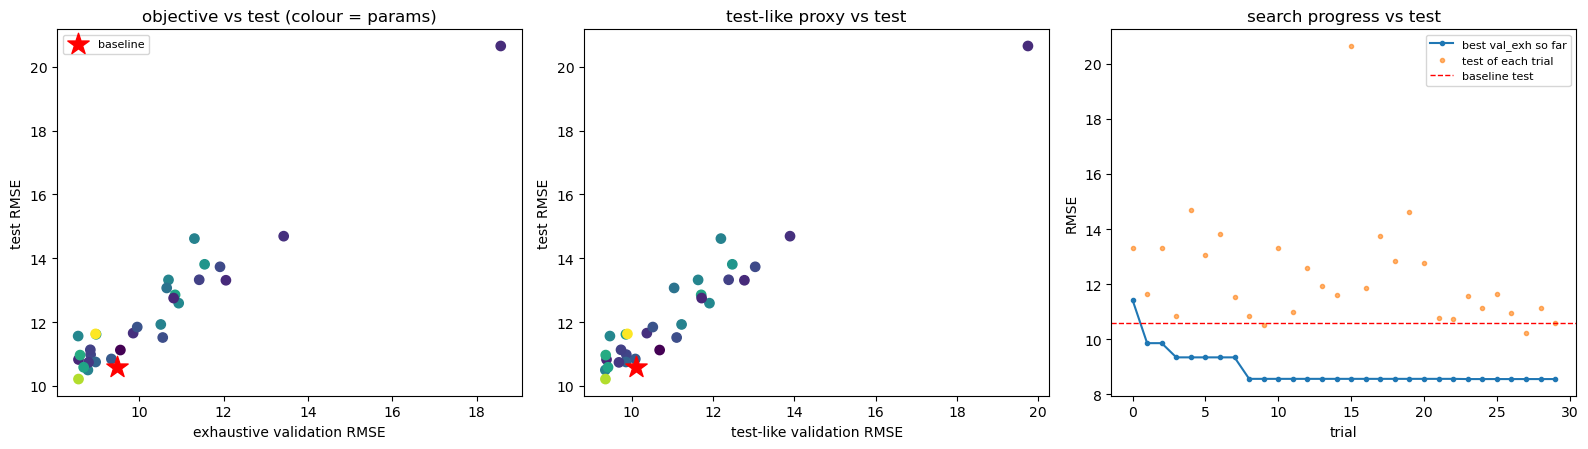

In [6]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(16,4.6))
ax[0].scatter(V,TE,c=T['params'],cmap='viridis',s=45)
ax[0].scatter([BASE['val_exh']],[BASE['test']],marker='*',s=260,c='red',label='baseline',zorder=5)
ax[0].set_xlabel('exhaustive validation RMSE'); ax[0].set_ylabel('test RMSE')
ax[0].set_title('objective vs test (colour = params)'); ax[0].legend(fontsize=8)
ax[1].scatter(TL,TE,c=T['params'],cmap='viridis',s=45)
ax[1].scatter([BASE['val_tl']],[BASE['test']],marker='*',s=260,c='red',zorder=5)
ax[1].set_xlabel('test-like validation RMSE'); ax[1].set_ylabel('test RMSE')
ax[1].set_title('test-like proxy vs test')
o=np.argsort(T['trial'].values)
ax[2].plot(T['trial'].values[o],np.minimum.accumulate(V[o]),marker='o',ms=3,label='best val_exh so far')
ax[2].plot(T['trial'].values[o],TE[o],marker='.',ls='',alpha=.6,label='test of each trial')
ax[2].axhline(BASE['test'],color='r',ls='--',lw=1,label='baseline test')
ax[2].set_xlabel('trial'); ax[2].set_ylabel('RMSE'); ax[2].legend(fontsize=8)
ax[2].set_title('search progress vs test')
plt.tight_layout(); plt.show()

## Objective bake-off — what should the real optimization minimise?

Every candidate objective below is computed from metrics the trials already recorded, so this
costs nothing extra. Each is scored by **regret**: the test RMSE of the configuration it would
have selected, minus the best test RMSE available anywhere in the trial set.

In [7]:
# ---- candidate objectives, all computed from what the trials already logged ----
def regret_of(score):
    i=int(np.argmin(score))
    return dict(sel_trial=int(T.trial.iloc[i]), test=float(TE[i]),
                rank=int((TE<TE[i]).sum())+1, regret=float(TE[i]-TE.min()))

P=T['params'].values/1e6
cands={'val_exh (current)':V, 'val_tl':TL,
       'mean(val_exh, val_tl)':0.5*V+0.5*TL,
       'rank-avg(val_exh, val_tl)':(pd.Series(V).rank()+pd.Series(TL).rank()).values/2}
for lam in (0.5,1.0,2.0):
    cands['val_exh + %.1f*params(M)'%lam]=V+lam*P
    cands['val_tl + %.1f*params(M)'%lam]=TL+lam*P

rows=[]
for nm,s in cands.items():
    r=regret_of(np.asarray(s,float)); r['objective']=nm; rows.append(r)
BK=pd.DataFrame(rows)[['objective','sel_trial','test','rank','regret']].sort_values('regret')
print('best test available in the trial set: %.3f (trial %d)'%(TE.min(),T.trial.iloc[int(np.argmin(TE))]))
print('baseline test                       : %.3f\n'%BASE['test'])
print(BK.to_string(index=False))
BEST_OBJ_NAME=BK.iloc[0]['objective']
print('\n-> lowest regret: %s'%BEST_OBJ_NAME)

# ---- does the recommended objective actually beat the baseline? ------------
best_score=np.asarray(cands[BEST_OBJ_NAME],float)
cand=T.iloc[int(np.argmin(best_score))]
CAND_KW={n:(int(cand[n]) if k=='int' else float(cand[n])) for n,_,_,k in SPACE}
print('\nconfiguration it selects (trial %d):'%cand['trial'])
for k_,v_ in CAND_KW.items(): print('   %-11s %s'%(k_,v_))

print('\nconfirmation on %d fresh seeds (neither config has seen these):'%FINAL_SEEDS)
res={}
for nm,kw in (('baseline',DEFAULTS),('recommended',CAND_KW)):
    rs=[evaluate(kw,SEED+1000+s) for s in range(FINAL_SEEDS)]
    res[nm]=dict(val_exh=float(np.mean([r['val_exh'] for r in rs])),
                 val_tl=float(np.mean([r['val_tl'] for r in rs])),
                 test=float(np.mean([r['test'] for r in rs])),
                 test_std=float(np.std([r['test'] for r in rs],ddof=1)),
                 test_best=float(np.min([r['test'] for r in rs])))
    print('  %-12s test %.3f +/- %.3f (best %.3f) | val_exh %.3f | val_tl %.3f'
          %(nm,res[nm]['test'],res[nm]['test_std'],res[nm]['test_best'],
            res[nm]['val_exh'],res[nm]['val_tl']))
d=res['recommended']['test']-res['baseline']['test']
noise=math.sqrt(res['recommended']['test_std']**2+res['baseline']['test_std']**2)
print('\ndifference %+.3f RMSE against combined seed noise %.3f -> %s'
      %(d,noise,'REAL' if abs(d)>noise else 'inside the noise, treat as a tie'))

json.dump(dict(baseline=BASE,trials=TRIALS,hp_corr=H.to_dict('records'),
               spearman_exh=float(spearmanr(V,TE)[0]),spearman_tl=float(spearmanr(TL,TE)[0]),
               bakeoff=BK.to_dict('records'),recommended_objective=BEST_OBJ_NAME,
               recommended_kw=CAND_KW,final=res),
          open('bo_diagnostic_fd003.json','w'),indent=2,default=str)
print('\nsaved bo_trials_fd003.csv and bo_diagnostic_fd003.json')

best test available in the trial set: 10.214 (trial 27)
baseline test                       : 10.578

                objective  sel_trial      test  rank   regret
    mean(val_exh, val_tl)         27 10.213994     1 0.000000
rank-avg(val_exh, val_tl)         27 10.213994     1 0.000000
                   val_tl          9 10.498081     2 0.284087
  val_exh + 0.5*params(M)          8 10.827337     6 0.613343
   val_tl + 0.5*params(M)          8 10.827337     6 0.613343
  val_exh + 1.0*params(M)          8 10.827337     6 0.613343
   val_tl + 1.0*params(M)          8 10.827337     6 0.613343
  val_exh + 2.0*params(M)          8 10.827337     6 0.613343
   val_tl + 2.0*params(M)          8 10.827337     6 0.613343
        val_exh (current)         23 11.561687    13 1.347693

-> lowest regret: mean(val_exh, val_tl)

configuration it selects (trial 27):
   filters     256
   lstm_units  74
   dense       256
   merged      384
   dropout     0.0
   lr          0.005
   l2reg       1e-07

